In [2]:
import pandas as pd
from scripts.extract_dataset import group_by_last_author
import matplotlib.pyplot as plt

# Importing ICLR OpenReview Dataset

In [3]:
iclr_df = pd.read_parquet("data/iclr26v1.parquet")
iclr_df.head()

,year,id,title,abstract,authors,author_ids,decision,scores,keywords,labels
0,2017,B1-Hhnslg,Prototypical Networks for Few-shot Learning,A recent approach to few-shot classification c...,"Jake Snell, Kevin Swersky, Richard Zemel",,Reject,"[6, 4, 5]","[deep learning, transfer learning]",transfer learning
1,2017,B1-q5Pqxl,Machine Comprehension Using Match-LSTM and Ans...,Machine comprehension of text is an important ...,"Shuohang Wang, Jing Jiang",,Accept (Poster),"[6, 6, 7]","[natural language processing, deep learning]",language models
2,2017,B16Jem9xe,Learning in Implicit Generative Models,Generative adversarial networks (GANs) provide...,"Shakir Mohamed, Balaji Lakshminarayanan",,Invite to Workshop Track,"[8, 7, 6]",[unsupervised learning],unlabeled
3,2017,B16dGcqlx,Third Person Imitation Learning,Reinforcement learning (RL) makes it possible ...,"Bradly C Stadie, Pieter Abbeel, Ilya Sutskever",,Accept (Poster),"[6, 5, 6]",[],unlabeled
4,2017,B184E5qee,Improving Neural Language Models with a Contin...,We propose an extension to neural network lang...,"Edouard Grave, Armand Joulin, Nicolas Usunier",,Accept (Poster),"[7, 9, 5]",[natural language processing],language models


# Group Papers by Principal Investigator (Last Listed Author)

Here we are assuming that the last author listed in `authors` is the Principal Investigators (PIs). We want to analyze the PIs because they have more publications than a new researcher.

In [4]:
pi_df = group_by_last_author(iclr_df)
pi_df.sort_values("num_papers", ascending=False).head()

,last_author,ids,titles,abstracts,collaborators,decisions,scores,keywords,labels,num_papers
9748,Sergey Levine,"[Bkul3t9ee, H1kjdOYlx, Hyq4yhile, SJ3rcZcxl, S...",[Unsupervised Perceptual Rewards for Imitation...,[Reward function design and exploration time a...,"[[Pierre Sermanet, Kelvin Xu], [Jacob Andreas,...","[Invite to Workshop Track, Invite to Workshop ...","[[6, 6, 4], [4, 3, 5], [6, 6, 7], [7, 7, 7, 8]...","[[computer vision, deep learning, unsupervised...","[transfer learning, transfer learning, transfe...",116
2127,Dacheng Tao,"[B1x6BTEKwr, r1xpF0VYDS, rkgg6xBYDH, rygRP2VYw...",[Piecewise linear activations substantially sh...,[Understanding the loss surface of a neural ne...,"[[Fengxiang He, Bohan Wang], [Kaining Zhang, M...","[Accept (Poster), Reject, Accept (Poster), Rej...","[[3, 6, 6], [3, 6, 6], [6, 6, 6], [3, 6, 3], [...","[[neural network, nonlinear activation, loss s...","[unlabeled, unlabeled, RNNs, unlabeled, few-sh...",88
12653,Yoshua Bengio,"[BJ0Ee8cxx, BJC_jUqxe, BJwFrvOeg, BkSmc8qll, S...","[Hierarchical Memory Networks, A STRUCTURED SE...",[Memory networks are neural networks with an e...,"[[Sarath Chandar, Sungjin Ahn, Hugo Larochelle...","[Reject, Accept (Poster), Reject, Reject, Acce...","[[5, 5, 4], [8, 5, 6], [6, 6, 6], [6, 7, 4], [...","[[deep learning, natural language processing],...","[language models, language models, language mo...",85
5640,Junchi Yan,"[rJlhYa4FPB, KLH36ELmwIB, drEe_dOHE_, gMRmCMoO...",[An Information Theoretic Perspective on Disen...,[Existing works on disentangled representation...,"[[Xiaojiang Yang, Wendong Bi, Yu Cheng], [Xian...","[Withdrawn, Accept (Poster), Withdrawn, Withdr...","[[3, 1, 1], [6, 6, 8, 6], [3, 4, 5, 6], [5, 5,...","[[], [neural architecture search, darts stabil...","[unlabeled, neural architecture search, GANs, ...",84
10955,Tom Goldstein,"[HkmaTz-0W, Skj8Kag0Z, BJgFcj0qKX, BJlr0j0ctX,...",[Visualizing the Loss Landscape of Neural Nets...,[Neural network training relies on our ability...,"[[Hao Li, Zheng Xu, Gavin Taylor], [Abhay Yada...","[Invite to Workshop Track, Accept (Poster), Wi...","[[5, 4, 5], [7, 9, 4], [5, 3, 5], [7, 4, 2], [...","[[visualization, loss surface, flatness, sharp...","[unlabeled, optimization, object detection, ad...",80


# Distribution of Papers per Author 

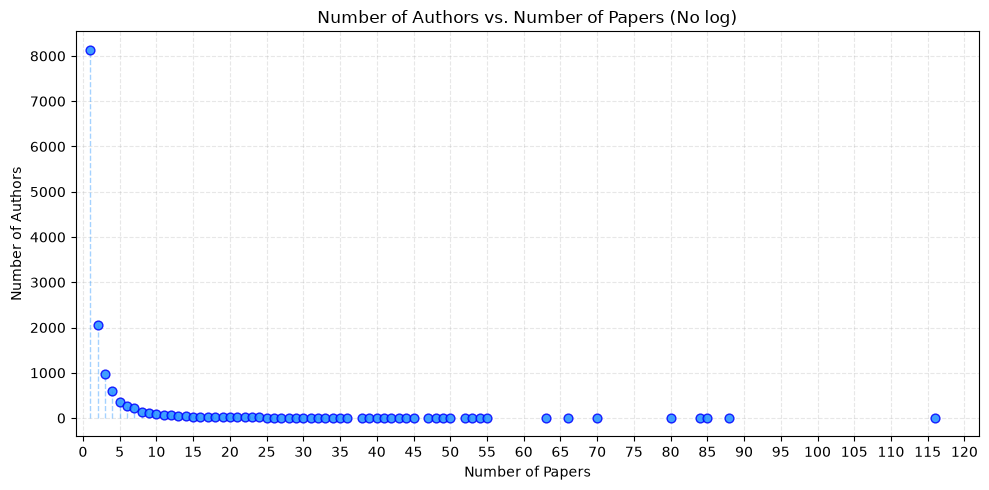

In [13]:
paper_freq = pi_df["num_papers"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

# Vertical line from x-axis (ymin=0) to each point
plt.vlines(
    x=paper_freq.index,
    ymin=0,
    ymax=paper_freq.values,
    color="dodgerblue",
    linestyle="--",
    alpha=0.4,
    linewidth=1,
)

# Scatter points
plt.scatter(
    paper_freq.index,
    paper_freq.values,
    color="dodgerblue",
    edgecolor="blue",
    alpha=0.85,
    s=40,
    zorder=3,
)

# More granular x-ticks (every 10 papers; or change to step 5 if preferred)
plt.xticks(range(0, 125, 5))
plt.xlim(left=-1, right=122)

plt.title("Number of Authors vs. Number of Papers (No log)")
plt.xlabel("Number of Papers")
plt.ylabel("Number of Authors")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

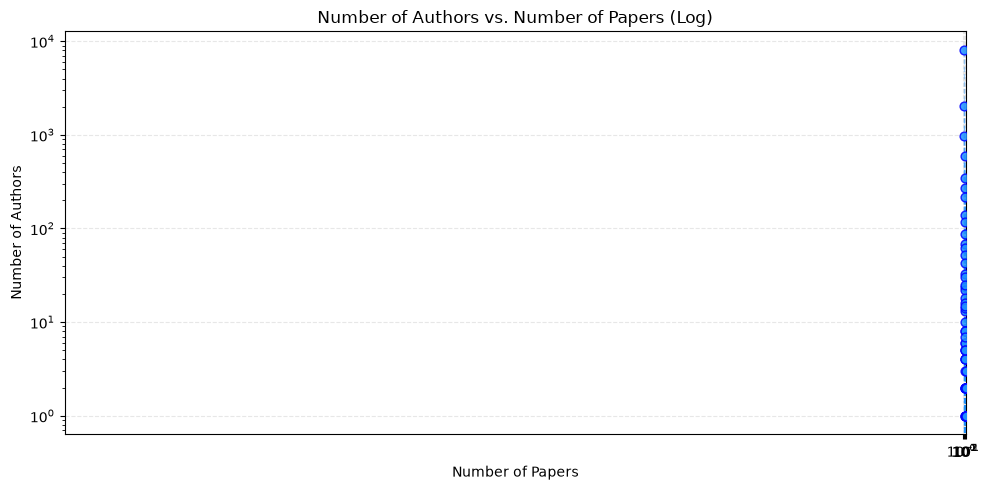

In [ ]:
paper_freq = pi_df["num_papers"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

# Vertical line from x-axis (ymin=0) to each point
plt.vlines(
    x=paper_freq.index,
    ymin=0,
    ymax=paper_freq.values,
    color="dodgerblue",
    linestyle="--",
    alpha=0.4,
    linewidth=1,
)

# Scatter points
plt.scatter(
    paper_freq.index,
    paper_freq.values,
    color="dodgerblue",
    edgecolor="blue",
    alpha=0.85,
    s=40,
    zorder=3,
)

# More granular x-ticks (every 10 papers; or change to step 5 if preferred)
plt.xticks(range(0, 125, 5))
plt.xlim(left=-1, right=122)

plt.xscale("log")
plt.yscale("log")

plt.title("Number of Authors vs. Number of Papers (Log)")
plt.xlabel("Number of Papers")
plt.ylabel("Number of Authors")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# Extracting External Publications via OpenAlex

We use the OpenAlex API (from `scripts.openAlex`) to fetch external papers outside of ICLR for authors in `pi_df`.
Given an author name and their ICLR seed paper, we retrieve their external paper titles and add `extra_papers` and `num_extra_papers` columns.

In [ ]:
from scripts.openAlex import fetch_papers_by_reference

def fetch_extra_titles_by_author(
    author_name: str,
    seed_title: str,
    email: str = "student@princeton.edu"
) -> list[str]:
    """Fetches external paper titles outside of ICLR for an author."""
    if not seed_title:
        return []
    try:
        papers = fetch_papers_by_reference(paper_title=seed_title, target_author=author_name, email=email)
        return [p["title"] for p in papers if p.get("title")]
    except Exception as error:
        print(f"Could not fetch papers for {author_name}: {error}")
        return []

def add_extra_papers_columns(
    df: pd.DataFrame,
    email: str = "student@princeton.edu"
) -> pd.DataFrame:
    """Adds extra_papers (list of titles) and num_extra_papers (count) to DataFrame."""
    result_df = df.copy()
    extra_titles_list = [
        fetch_extra_titles_by_author(
            author_name=row["last_author"],
            seed_title=row["titles"][0] if row["titles"] else "",
            email=email
        )
        for _, row in result_df.iterrows()
    ]
    result_df["extra_papers"] = extra_titles_list
    result_df["num_extra_papers"] = [len(titles) for titles in extra_titles_list]
    return result_df

# Example: Populate extra papers for top 5 PIs in pi_df
top_pi_df = pi_df.sort_values("num_papers", ascending=False).head(5)
pi_with_extra_df = add_extra_papers_columns(top_pi_df)
pi_with_extra_df[["last_author", "num_papers", "num_extra_papers", "extra_papers"]]


,last_author,num_papers,num_extra_papers,extra_papers
9748,Sergey Levine,116,196,[End-to-end training of deep visuomotor polici...
2127,Dacheng Tao,88,200,"[A Survey on Vision Transformer, Knowledge Dis..."
12653,Yoshua Bengio,85,197,"[Deep learning, Gradient-based learning applie..."
5640,Junchi Yan,84,199,[R3Det: Refined Single-Stage Detector with Fea...
10955,Tom Goldstein,80,199,[The Split Bregman Method for L1-Regularized P...
